# Descarga y configuración del Dataset

In [16]:
import os
import glob
import kagglehub

import numpy as np
from PIL import Image
import matplotlib.pyplot as plt
import cv2

Descargamos el dataset multimodal de tumores cerebrales (CT y MRI).

In [17]:
# Descarga del dataset utilizando la API de kagglehub
path_dataset = kagglehub.dataset_download("murtozalikhon/brain-tumor-multimodal-image-ct-and-mri")
print("Ruta local del dataset descargado:", path_dataset)

Ruta local del dataset descargado: C:\Users\lukas\.cache\kagglehub\datasets\murtozalikhon\brain-tumor-multimodal-image-ct-and-mri\versions\1


Para este taller de análisis de Resonancia Magnética, filtraremos la base de datos para aislar únicamente las carpetas correspondientes a MRI, dividiendo las imágenes en dos categorías principales: Sanos (Healthy) y Tumor (Tumor).

In [18]:
# Definir rutas de acceso específicas para la modalidad MRI
mri_base_path = os.path.join(path_dataset, 'Dataset', 'Brain Tumor MRI images')
mri_healthy_dir = os.path.join(mri_base_path, 'Healthy')
mri_tumor_dir = os.path.join(mri_base_path, 'Tumor')

# Obtener y ordenar todas las rutas de imágenes correspondientes
mri_sanas_total = sorted(glob.glob(os.path.join(mri_healthy_dir, '*.*')))
mri_tumor_total = sorted(glob.glob(os.path.join(mri_tumor_dir, '*.*')))

print(f"Total de imágenes de MRI de control (Sanas): {len(mri_sanas_total)}")
print(f"Total de imágenes de MRI patológicas (Tumor): {len(mri_tumor_total)}")

Total de imágenes de MRI de control (Sanas): 2000
Total de imágenes de MRI patológicas (Tumor): 3000


Modificando los índices en la siguiente lista, podrás seleccionar 3 casos sanos y 3 casos tumorosos para visualizar y contrastar la anatomía cerebral.

In [19]:
indices_sanos = [120, 600, 1400]      # Índices válidos entre 0 y 1999
indices_tumores = [0, 100, 800]       # Índices válidos entre 0 y 2999

Añadiremos ruido al conjunto de datos mediante artefactos visuales que dificulten la diferenciación de características en las imágenes.

In [20]:
def añadir_ruido_sal_pimienta(imagen_pil, cantidad_sal=0.02, cantidad_pimienta=0.02):
    # Convertir a escala de grises y a matriz numpy para manipular píxeles
    img_gray = imagen_pil.convert('L')
    img_np = np.array(img_gray)
    img_ruido = img_np.copy()

    # Píxeles de sal (Blancos - 255)
    num_sal = np.ceil(cantidad_sal * img_np.size)
    coords_sal = [np.random.randint(0, i - 1, int(num_sal)) for i in img_np.shape]
    img_ruido[tuple(coords_sal)] = 255

    # Píxeles de pimienta (Negros - 0)
    num_pimienta = np.ceil(cantidad_pimienta * img_np.size)
    coords_pimienta = [np.random.randint(0, i - 1, int(num_pimienta)) for i in img_np.shape]
    img_ruido[tuple(coords_pimienta)] = 0

    return img_ruido

A continuación, puedes visualizar y contrastar la anatomía cerebral de los casos seleccionados previamente, con el ruido añadido.

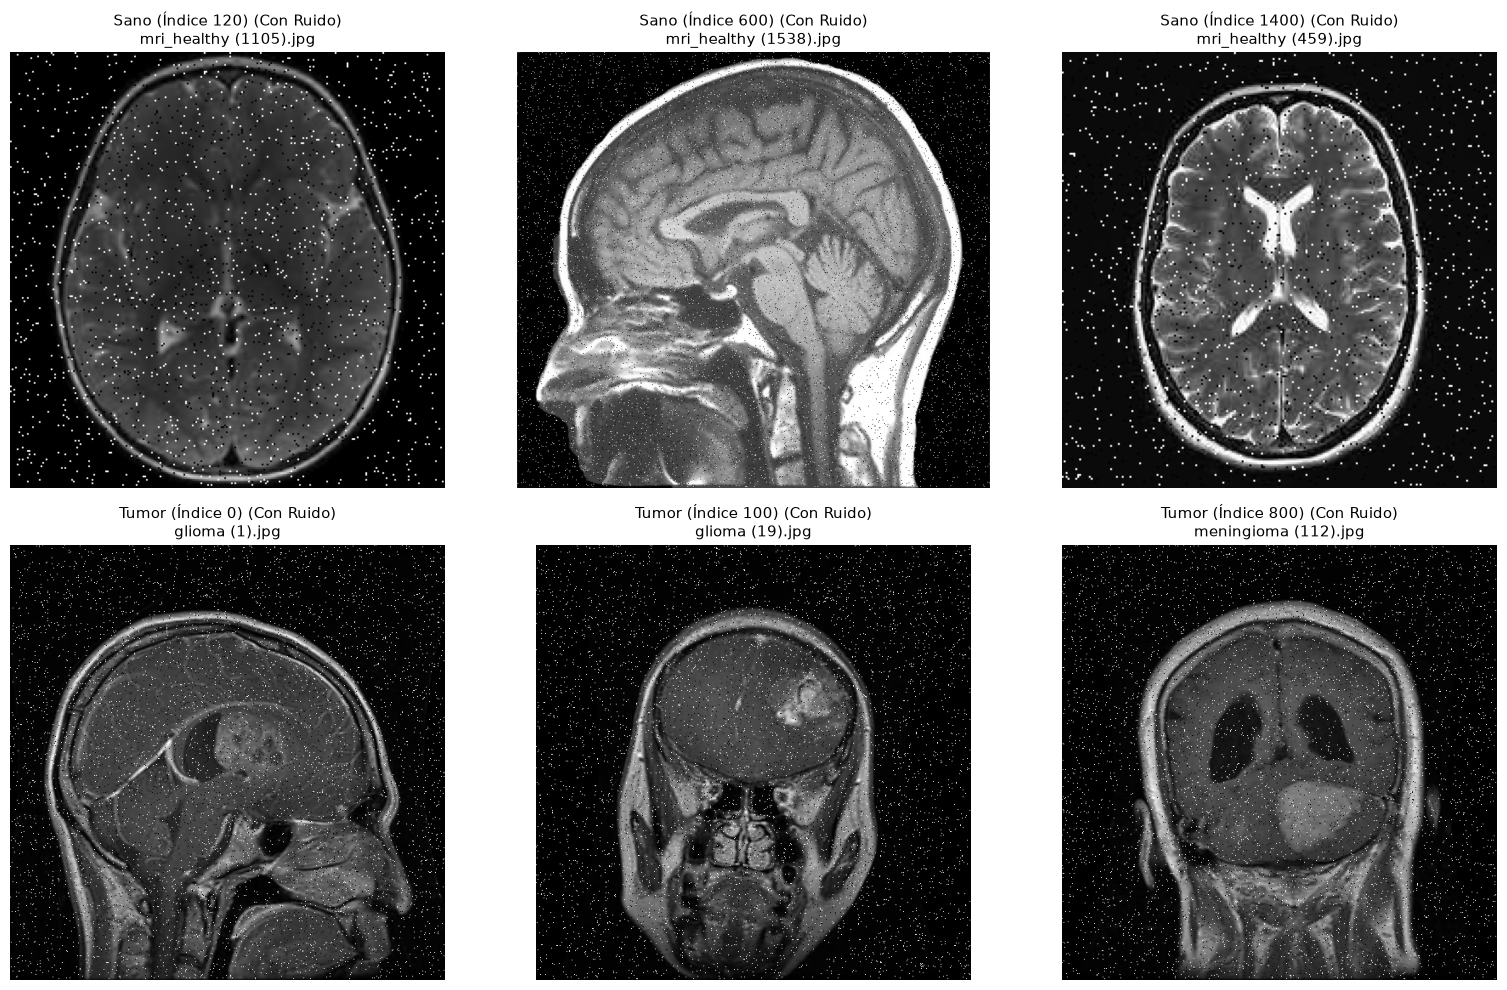

In [21]:
# Selección de las muestras aplicando la validación de rango
muestras_sanas = [mri_sanas_total[i % len(mri_sanas_total)] for i in indices_sanos]
muestras_tumores = [mri_tumor_total[i % len(mri_tumor_total)] for i in indices_tumores]

# Consolidar imágenes y etiquetas para la graficación
imagenes = muestras_sanas + muestras_tumores
etiquetas = [f"Sano (Índice {i})" for i in indices_sanos] + [f"Tumor (Índice {i})" for i in indices_tumores]

# Graficar el panel comparativo añadiendo ruido
fig, axes = plt.subplots(2, 3, figsize=(16, 10))
axes = axes.flatten()

# Fijar semilla para reproducibilidad del ruido
np.random.seed(42)

for idx, (ruta_img, etiqueta) in enumerate(zip(imagenes, etiquetas)):
    img_original = Image.open(ruta_img)
    img_con_ruido = añadir_ruido_sal_pimienta(img_original, cantidad_sal=0.02, cantidad_pimienta=0.02)

    axes[idx].imshow(img_con_ruido, cmap='gray')
    axes[idx].set_title(f"{etiqueta} (Con Ruido)\n{os.path.basename(ruta_img)}", fontsize=11)
    axes[idx].axis('off')

plt.tight_layout()
plt.show()

# Desarrollo

**Actividad 1:** Habiendo cargado exitosamente las imágenes, verifica el formato, las dimensiones y las características visuales del conjunto de datos.

In [22]:
# Fijamos la misma semilla de la celda anterior: el ruido generado es idéntico al visualizado
np.random.seed(42)

imgs_originales = []   # imágenes limpias en escala de grises (uint8)
imgs_ruido = []        # imágenes con ruido sal y pimienta (uint8)
formatos = []

for ruta in imagenes:
    pil = Image.open(ruta)
    formatos.append((pil.format, pil.mode))
    imgs_originales.append(np.array(pil.convert('L')))
    imgs_ruido.append(añadir_ruido_sal_pimienta(pil, cantidad_sal=0.02, cantidad_pimienta=0.02))

# Resumen de formato, dimensiones y estadísticos de cada imagen
print(f"{'Imagen':<22}{'Formato':<9}{'Modo':<6}{'Dim (alto x ancho)':<20}{'dtype':<8}{'min':>5}{'max':>5}{'media':>9}")
for et, (fmt, modo), im in zip(etiquetas, formatos, imgs_originales):
    print(f"{et:<22}{str(fmt):<9}{modo:<6}{str(im.shape):<20}{str(im.dtype):<8}{im.min():>5}{im.max():>5}{im.mean():>9.2f}")

Imagen                Formato  Modo  Dim (alto x ancho)  dtype     min  max    media
Sano (Índice 120)     JPEG     RGB   (256, 256)          uint8       0  219    38.74
Sano (Índice 600)     JPEG     RGB   (602, 655)          uint8       0  255    97.33
Sano (Índice 1400)    JPEG     RGB   (225, 225)          uint8       0  255    53.60
Tumor (Índice 0)      JPEG     RGB   (512, 512)          uint8       0  255    42.08
Tumor (Índice 100)    JPEG     RGB   (512, 512)          uint8       0  255    31.01
Tumor (Índice 800)    JPEG     RGB   (512, 512)          uint8       0  255    40.13


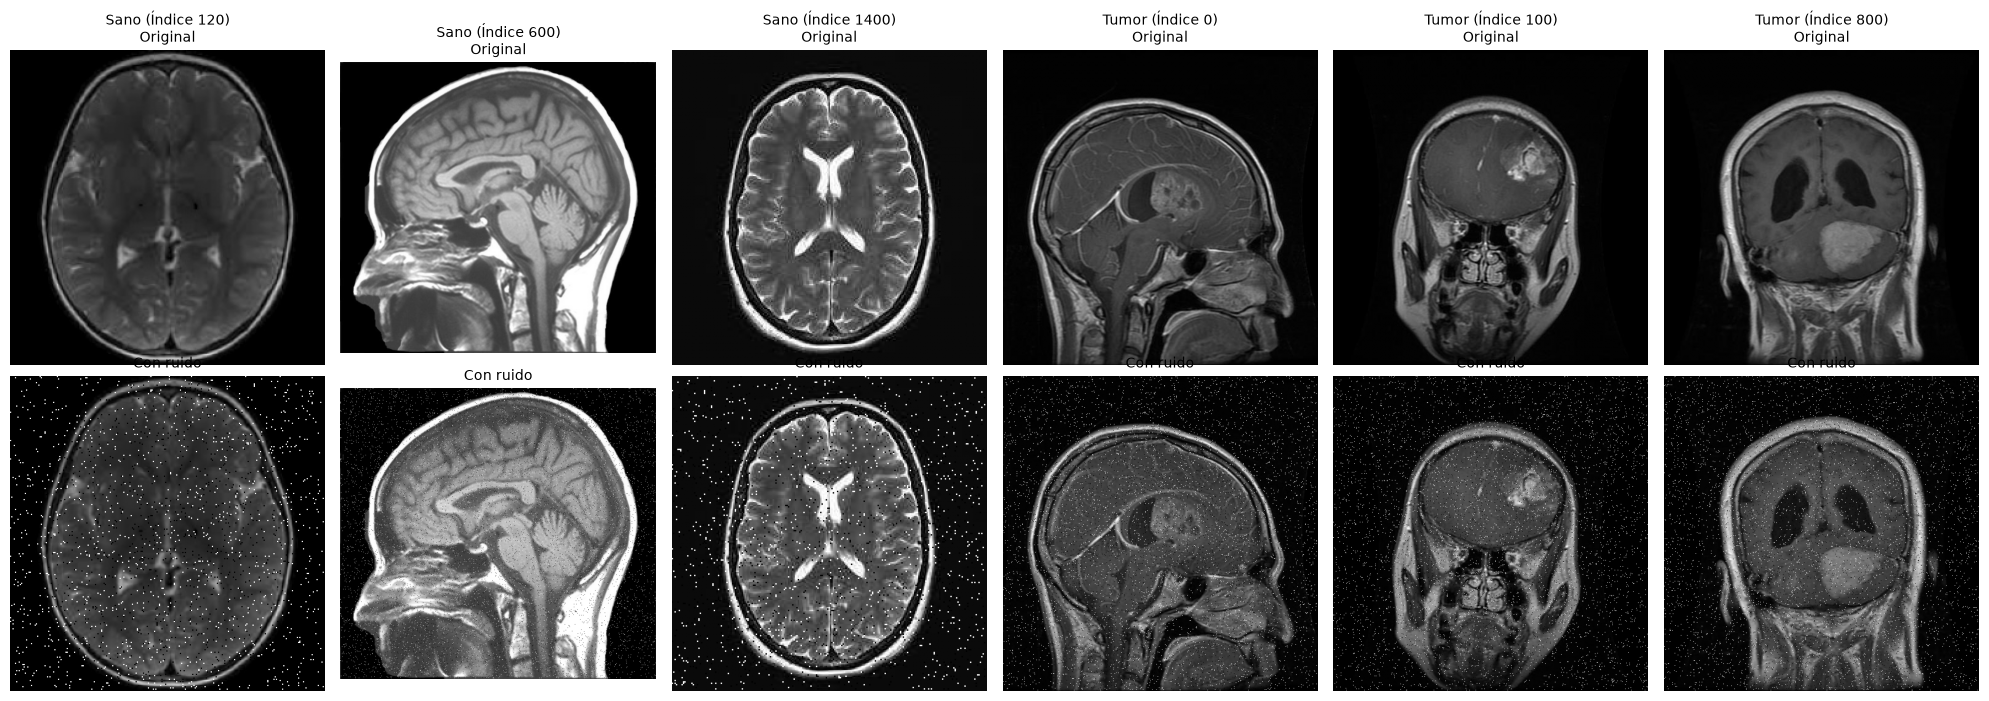

In [23]:
# Visualización: fila superior = original, fila inferior = con ruido
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for j, et in enumerate(etiquetas):
    axes[0, j].imshow(imgs_originales[j], cmap='gray', vmin=0, vmax=255)
    axes[0, j].set_title(f"{et}\nOriginal", fontsize=10)
    axes[1, j].imshow(imgs_ruido[j], cmap='gray', vmin=0, vmax=255)
    axes[1, j].set_title("Con ruido", fontsize=10)
    axes[0, j].axis('off'); axes[1, j].axis('off')
plt.tight_layout()
plt.show()

**Observaciones:** Las imágenes de la fila superior corresponden a los MRI originales y las de la fila inferior a esas mismas imágenes con ruido sal y pimienta añadido a propósito (2 % sal y 2 % pimienta). Sirve para ver evaluar limpieza. 

**Actividad 2:** Aplica un filtro de mediana a las imágenes. Este filtro asigna a cada píxel la mediana de los valores dentro de una ventana (por ejemplo, de 3 $\times$ 3), permitiendo eliminar el ruido impulsivo sin afectar significativamente los bordes

In [24]:
KSIZE = 3  # ventana de 3 x 3

imgs_filtradas = [cv2.medianBlur(im, KSIZE) for im in imgs_ruido]   # filtro de mediana
imgs_media     = [cv2.blur(im, (KSIZE, KSIZE)) for im in imgs_ruido] # filtro de media (comparación)

# PSNR respecto a la imagen original: mayor valor = más parecida a la original
print(f"{'Imagen':<22}{'Ruido':>10}{'Mediana':>10}{'Media':>10}   (PSNR en dB)")
for et, o, r, m_, a in zip(etiquetas, imgs_originales, imgs_ruido, imgs_filtradas, imgs_media):
    print(f"{et:<22}{cv2.PSNR(o, r):>10.2f}{cv2.PSNR(o, m_):>10.2f}{cv2.PSNR(o, a):>10.2f}")

Imagen                     Ruido   Mediana     Media   (PSNR en dB)
Sano (Índice 120)          18.15     37.16     26.43
Sano (Índice 600)          18.61     41.35     27.26
Sano (Índice 1400)         18.20     26.65     22.77
Tumor (Índice 0)           18.21     40.43     26.91
Tumor (Índice 100)         17.86     41.56     26.63
Tumor (Índice 800)         18.08     43.18     26.94


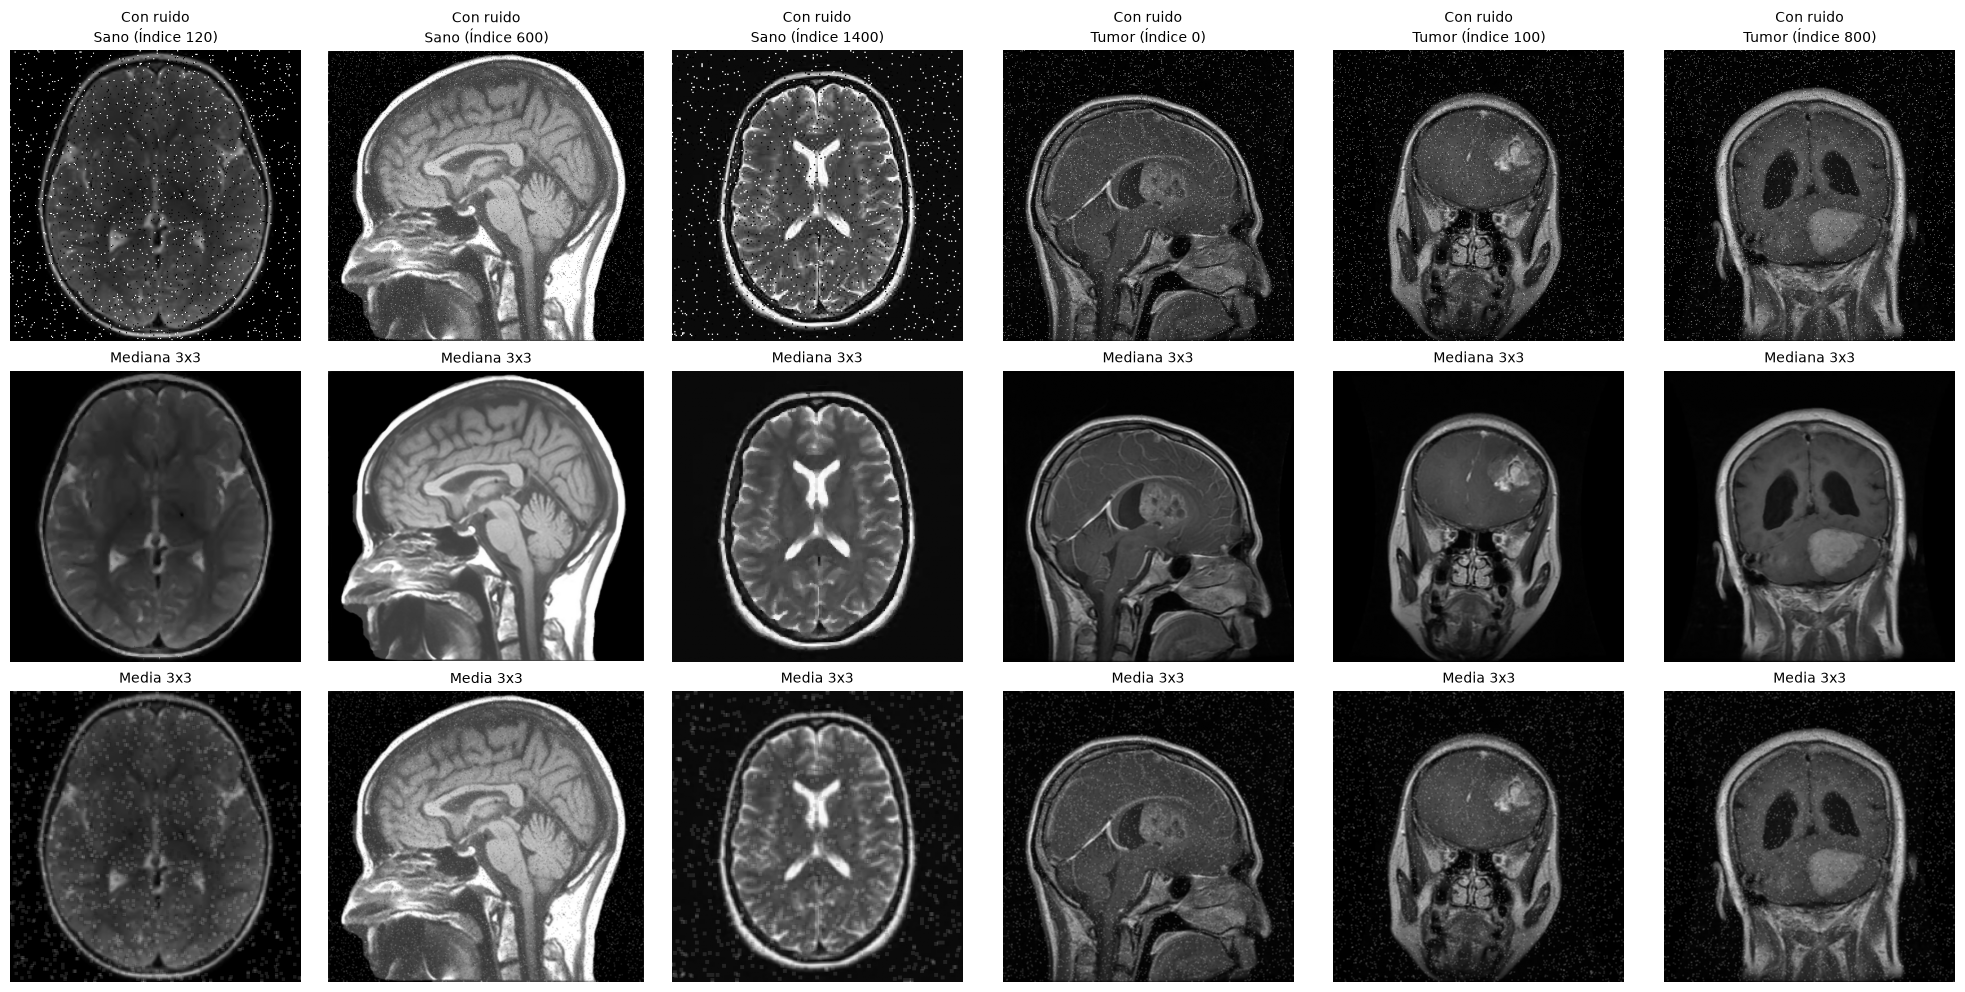

In [25]:
filas = [("Con ruido", imgs_ruido), (f"Mediana {KSIZE}x{KSIZE}", imgs_filtradas), (f"Media {KSIZE}x{KSIZE}", imgs_media)]
fig, axes = plt.subplots(3, 6, figsize=(20, 10))
for i, (nombre, lista) in enumerate(filas):
    for j in range(6):
        axes[i, j].imshow(lista[j], cmap='gray', vmin=0, vmax=255)
        axes[i, j].axis('off')
        axes[i, j].set_title(f"{nombre}\n{etiquetas[j]}" if i == 0 else nombre, fontsize=10)
plt.tight_layout()
plt.show()

**Observaciones:** el filtro de mediana elimina casi todos los puntos de sal y pimienta y conserva los bordes del cráneo y del cerebro, el filtro de media deja manchas grises donde había ruido y difumina los bordes. Esto se ve también en el PSNR (compara las columnas de la tabla). A partir de aquí se trabaja con `imgs_filtradas`.

**Actividad 3:** Genera el histograma de intesidad para cada imagen. Analiza la diferencia entre el cerebro y otras estructuras, e intenta identificar los rangos de intensidad que caracterizan las regiones de interés.

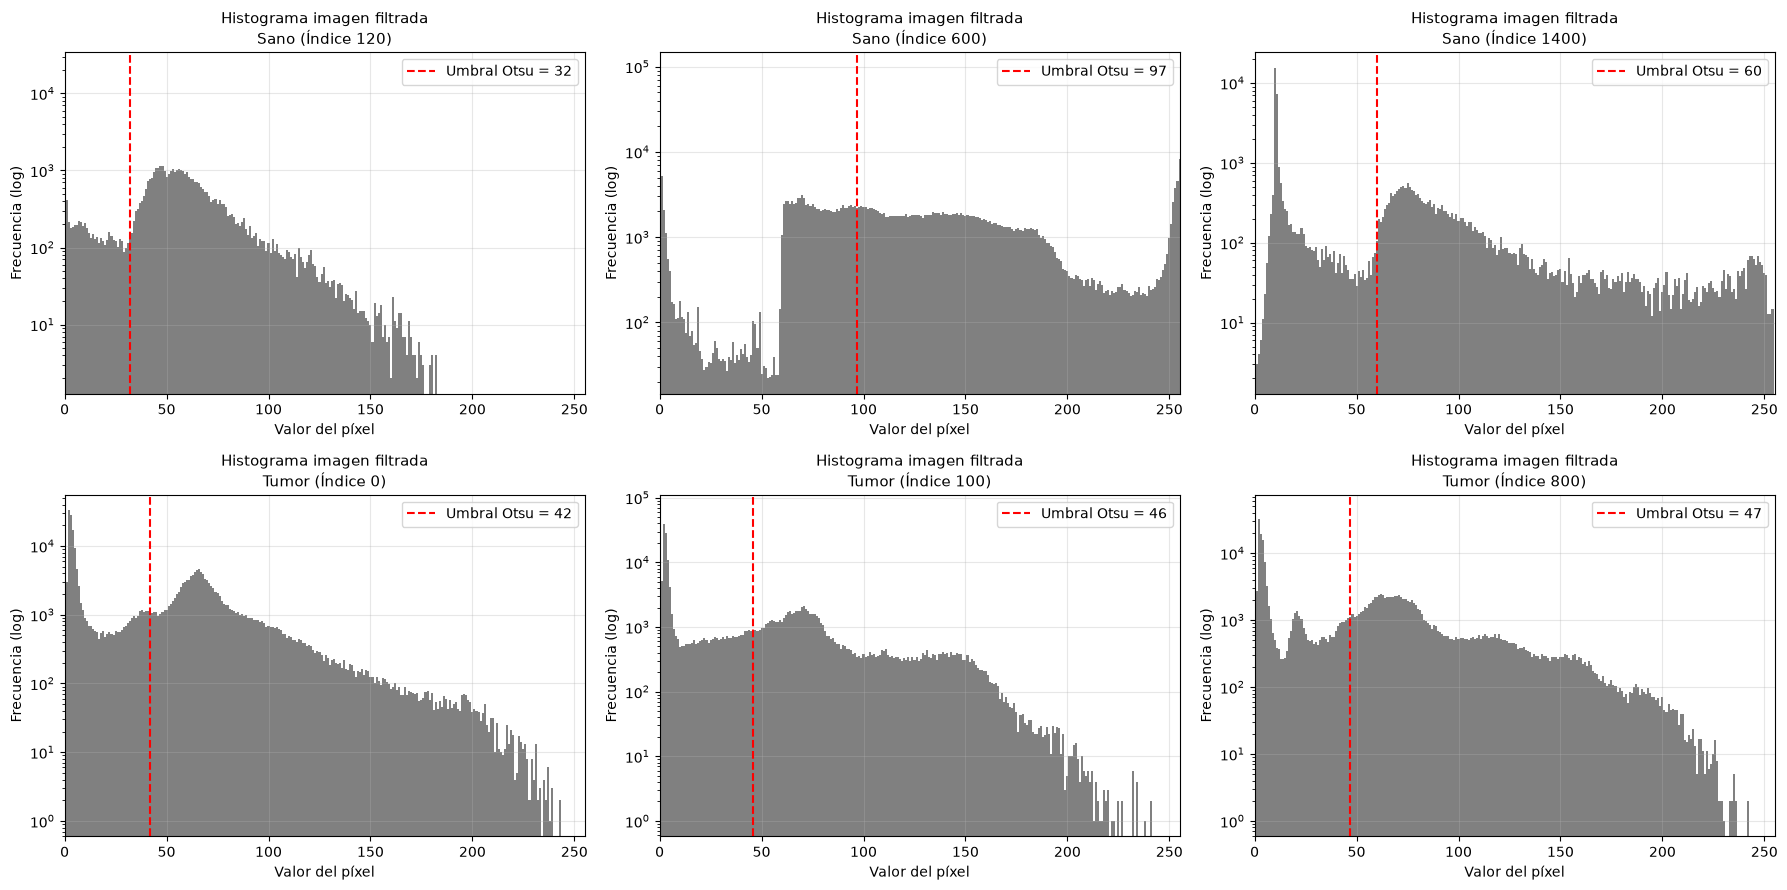

In [26]:
umbrales_otsu_hist = []

fig, axes = plt.subplots(2, 3, figsize=(18, 9))
for ax, im, et in zip(axes.flatten(), imgs_filtradas, etiquetas):
    hist = cv2.calcHist([im], [0], None, [256], [0, 256]).ravel()
    t_o, _ = cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    umbrales_otsu_hist.append(t_o)

    ax.bar(np.arange(256), hist, width=1.0, color='gray')
    ax.axvline(t_o, color='r', linestyle='--', label=f"Umbral Otsu = {int(t_o)}")
    ax.set_yscale('log')
    ax.set_xlim(0, 255)
    ax.set_title(f"Histograma imagen filtrada\n{et}", fontsize=11)
    ax.set_xlabel("Valor del píxel"); ax.set_ylabel("Frecuencia (log)")
    ax.legend()
    ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

**Análisis:** completa observando tus histogramas. Normalmente se aprecia (i) un pico muy alto en intensidades bajas, que corresponde al fondo; (ii) una zona intermedia más ancha, que corresponde al tejido cerebral; y (iii) intensidades altas, que corresponden al cráneo/cuero cabelludo y a otras estructuras brillantes. Anota el rango aproximado de cada región y úsalo para elegir el umbral manual de la Actividad 4.

**Actividad 4:** Crea una máscara binaria del cerebro mediante un proceso de binarización. Este puede realizarse de forma manual, seleccionando un umbral a partir del histograma, o mediante un método automático como el de [Otsu](https://docs.opencv.org/4.x/d7/d4d/tutorial_py_thresholding.html).

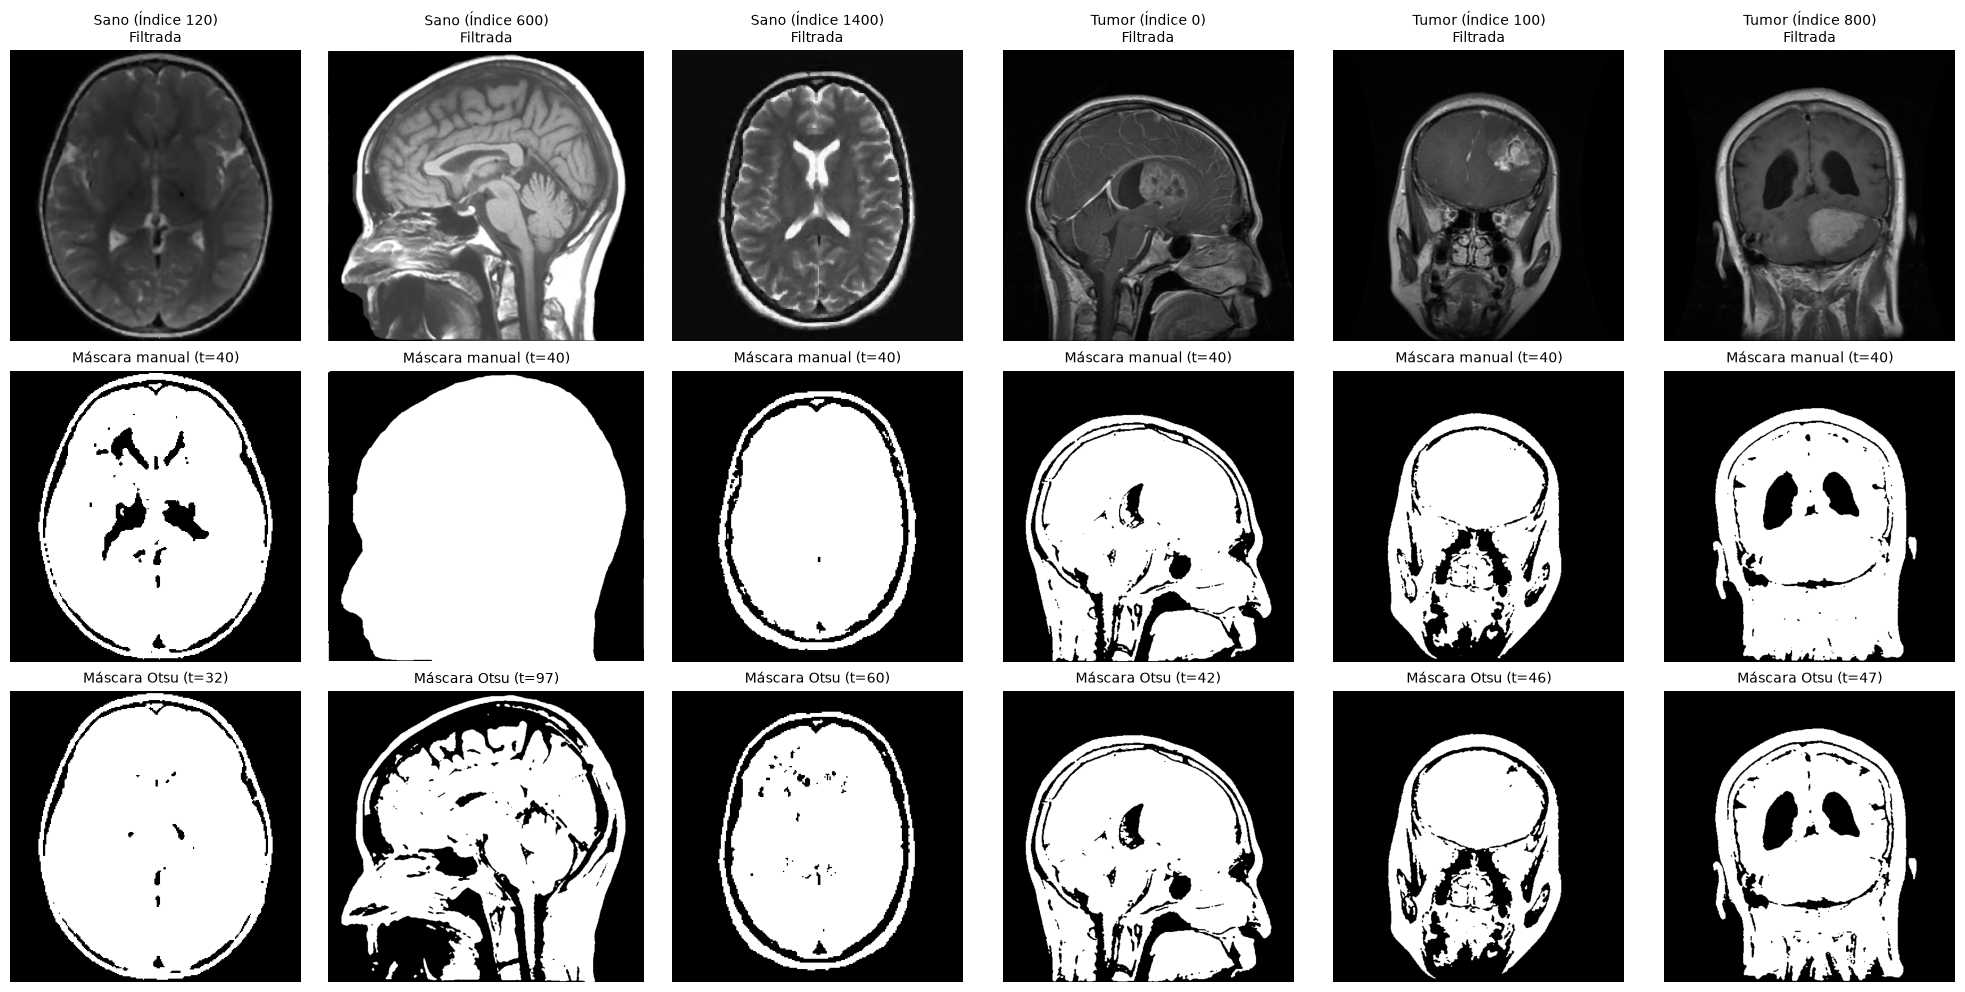

In [27]:
UMBRAL_MANUAL = 40   # <-- ajústalo mirando los histogramas de la Actividad 3

masks_manual, masks_otsu, umbrales_otsu = [], [], []
for im in imgs_filtradas:
    _, mm = cv2.threshold(im, UMBRAL_MANUAL, 255, cv2.THRESH_BINARY)
    t_o, mo = cv2.threshold(im, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    masks_manual.append(mm)
    masks_otsu.append(mo)
    umbrales_otsu.append(int(t_o))

fig, axes = plt.subplots(3, 6, figsize=(20, 10))
for j in range(6):
    axes[0, j].imshow(imgs_filtradas[j], cmap='gray', vmin=0, vmax=255)
    axes[0, j].set_title(f"{etiquetas[j]}\nFiltrada", fontsize=10)
    axes[1, j].imshow(masks_manual[j], cmap='gray', vmin=0, vmax=255)
    axes[1, j].set_title(f"Máscara manual (t={UMBRAL_MANUAL})", fontsize=10)
    axes[2, j].imshow(masks_otsu[j], cmap='gray', vmin=0, vmax=255)
    axes[2, j].set_title(f"Máscara Otsu (t={umbrales_otsu[j]})", fontsize=10)
    for i in range(3): axes[i, j].axis('off')
plt.tight_layout()
plt.show()

**Actividad 5:** Aplica la máscara binaria obtenida sobre la imagen filtrada para extraer únicamente el cerebro y eliminar las estructuras externas. Compara lado a lado la imagen filtrada, la máscara, y la imagen final.

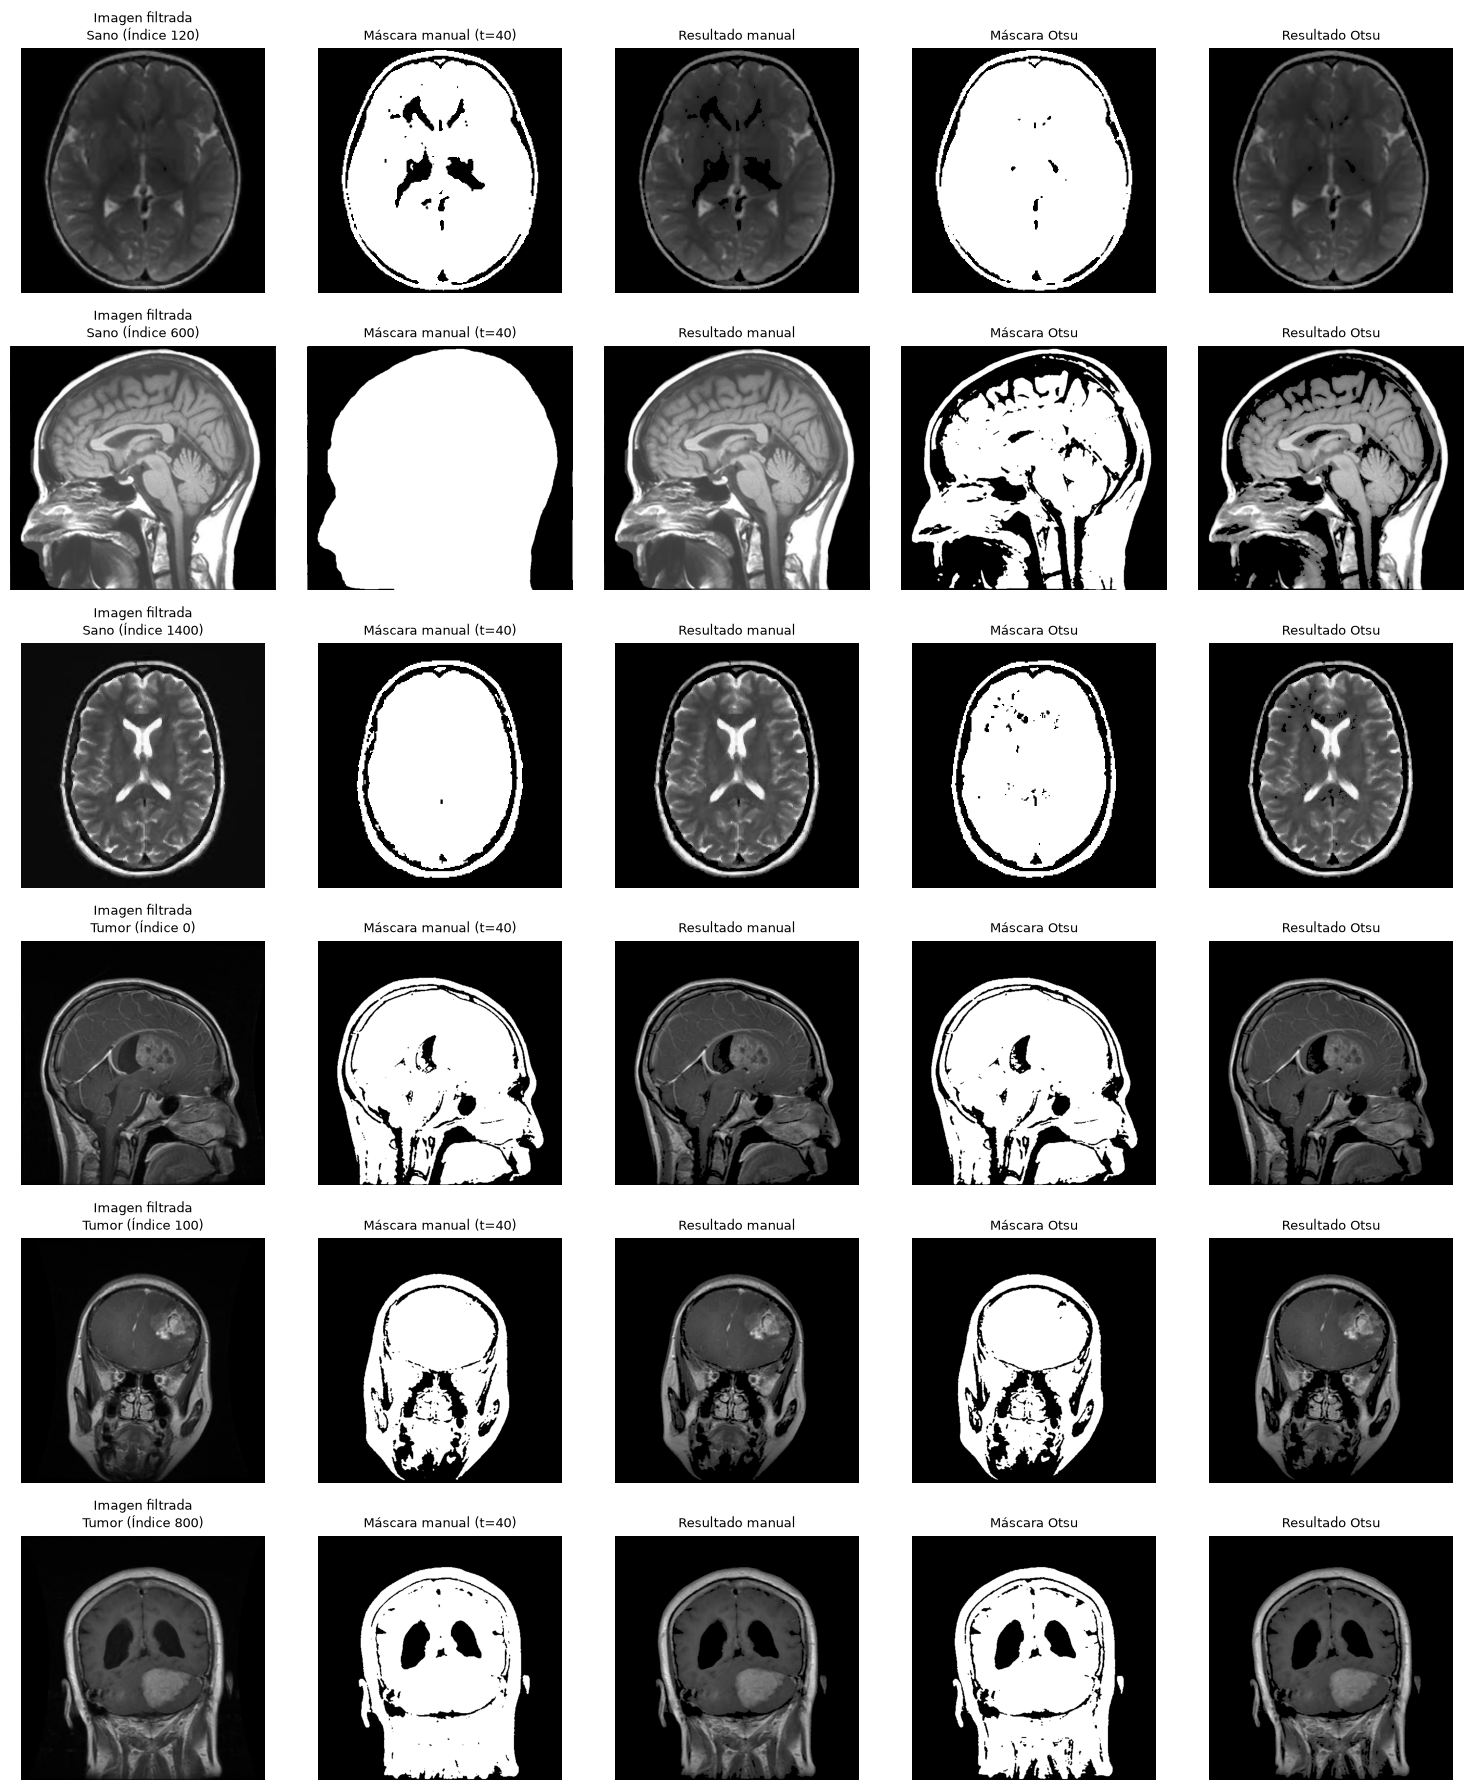

In [28]:
res_manual = [cv2.bitwise_and(im, im, mask=m) for im, m in zip(imgs_filtradas, masks_manual)]
res_otsu   = [cv2.bitwise_and(im, im, mask=m) for im, m in zip(imgs_filtradas, masks_otsu)]

fig, axes = plt.subplots(6, 5, figsize=(15, 18))
cols = ["Imagen filtrada", f"Máscara manual (t={UMBRAL_MANUAL})", "Resultado manual", "Máscara Otsu", "Resultado Otsu"]
for i in range(6):
    paneles = [imgs_filtradas[i], masks_manual[i], res_manual[i], masks_otsu[i], res_otsu[i]]
    for k, p in enumerate(paneles):
        axes[i, k].imshow(p, cmap='gray', vmin=0, vmax=255)
        axes[i, k].axis('off')
        axes[i, k].set_title(f"{cols[k]}\n{etiquetas[i]}" if k == 0 else cols[k], fontsize=9)
plt.tight_layout()
plt.show()

**Actividad 6:** Analiza los resultados y evalúa la efectividad de la umbralización realizada de acuerdo al objetivo original. ¿Observas diferencias entre la umbralización según el ángulo de la imagen, el estado del paciente u otros factores?

In [29]:
def dice(a, b):
    """Coeficiente de Dice entre dos máscaras binarias (1 = idénticas)."""
    a, b = a > 0, b > 0
    return 2 * np.logical_and(a, b).sum() / (a.sum() + b.sum())

print(f"{'Imagen':<22}{'t Otsu':>8}{'% área manual':>15}{'% área Otsu':>13}{'Dice (man vs Otsu)':>20}")
for et, t_o, mm, mo in zip(etiquetas, umbrales_otsu, masks_manual, masks_otsu):
    print(f"{et:<22}{t_o:>8}{100 * (mm > 0).mean():>15.1f}{100 * (mo > 0).mean():>13.1f}{dice(mm, mo):>20.3f}")

Imagen                  t Otsu  % área manual  % área Otsu  Dice (man vs Otsu)
Sano (Índice 120)           32           55.1         59.4               0.963
Sano (Índice 600)           97           72.4         49.9               0.817
Sano (Índice 1400)          60           44.1         42.0               0.977
Tumor (Índice 0)            42           49.8         48.9               0.991
Tumor (Índice 100)          46           33.1         31.1               0.969
Tumor (Índice 800)          47           43.7         41.1               0.969


**Análisis de resultados** (contrasta cada punto con tus figuras y con la tabla anterior):

* **Efectividad respecto al objetivo.** El objetivo era aislar el cerebro del resto de estructuras. Una umbralización global separa bien el fondo negro del tejido, pero el cráneo y el cuero cabelludo tienen intensidades altas (a veces mayores que las del cerebro), así que pasan el umbral y **quedan dentro de la máscara**. Además, el tejido cerebral tiene intensidades muy variables (sustancia gris, blanca, líquido cefalorraquídeo), por lo que parte del cerebro cae bajo el umbral y la máscara queda con huecos.
* **Manual vs. Otsu.** Otsu asume un histograma bimodal. Aquí el fondo concentra la mayor parte de los píxeles, por lo que el umbral de Otsu suele separar "fondo" de "todo lo demás" y no "cerebro" de "otras estructuras". Con un umbral manual elegido en el histograma se controla mejor qué se incluye, pero el valor depende de cada imagen. Los valores de Dice y de % de área de la tabla cuantifican cuánto difieren ambos métodos.
* **Ángulo de adquisición y estado del paciente.** Cambiar el corte cambia las estructuras visibles (más o menos cráneo, ojos, senos) y por lo tanto el histograma, así que un mismo umbral fijo no funciona igual en todas las imágenes. En las imágenes con tumor, la lesión tiene una intensidad distinta a la del tejido sano: puede quedar excluida o incluida según el umbral, y cambia la forma del histograma y el umbral de Otsu. Compara el `t Otsu` y el % de área entre las tres imágenes sanas y las tres con tumor.
* **Limitaciones y mejoras posibles.** Un umbral global no usa información espacial. Para aislar de verdad el cerebro se suele combinar con operaciones morfológicas (apertura/erosión para separar el cráneo, quedarse con la componente conexa más grande y rellenar huecos) o con umbrales locales/adaptativos.

### Bonus

**Opción 1:** Ajusta la umbralización para segmentar más de una estructura de la imagen, evaluando factibilidad y posibles desafíos.

**Opción 2:** Implementa un filtro de detección de bordes basado en un operador Laplaciano, Sobel o Prewitt, justificando tu decisión.

**Opción 3:** Investiga y realiza otro procedimiento que considere el uso de cálculos básicos de álgebra lineal o cálculo diferencial.

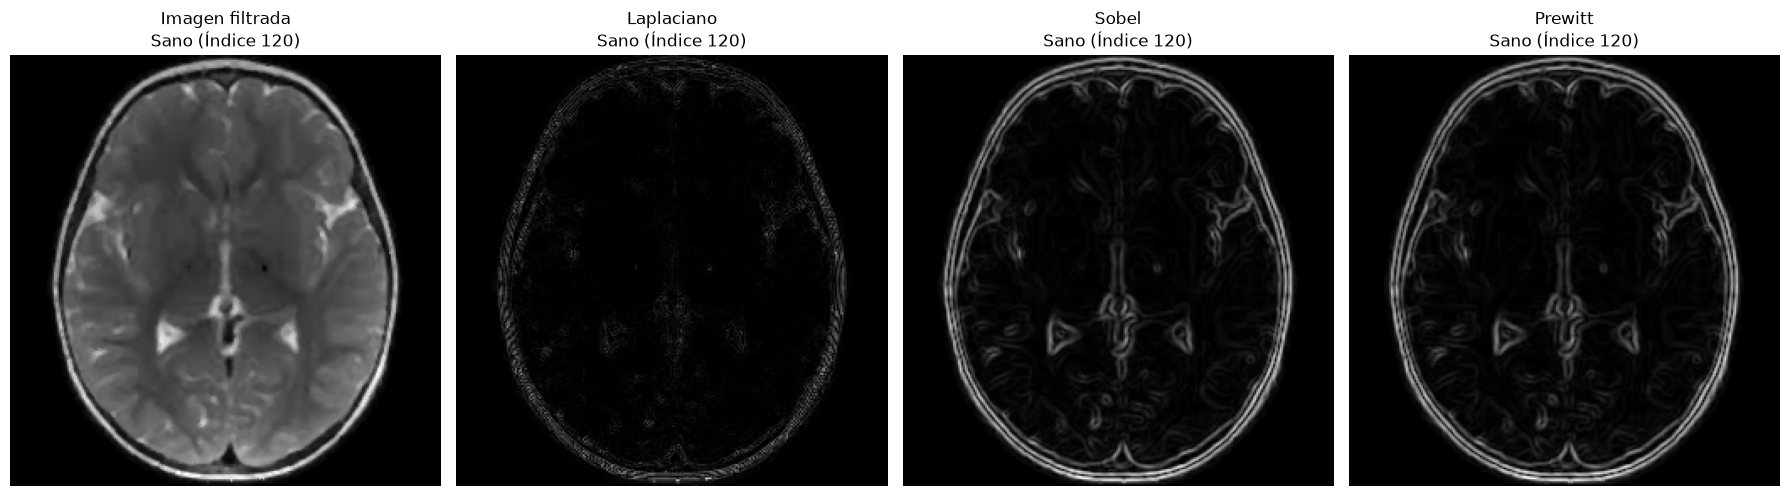

In [30]:
def a_uint8(arr):
    """Normaliza a 0-255 para poder visualizar."""
    return cv2.normalize(np.abs(arr), None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

def sobel_mag(im):
    gx = cv2.Sobel(im, cv2.CV_64F, 1, 0, ksize=3)
    gy = cv2.Sobel(im, cv2.CV_64F, 0, 1, ksize=3)
    return a_uint8(cv2.magnitude(gx, gy))

def prewitt_mag(im):
    kx = np.array([[-1, 0, 1], [-1, 0, 1], [-1, 0, 1]], dtype=np.float64)
    ky = np.array([[-1, -1, -1], [0, 0, 0], [1, 1, 1]], dtype=np.float64)
    gx = cv2.filter2D(im, cv2.CV_64F, kx)
    gy = cv2.filter2D(im, cv2.CV_64F, ky)
    return a_uint8(cv2.magnitude(gx, gy))

def laplaciano(im):
    return a_uint8(cv2.Laplacian(im, cv2.CV_64F, ksize=1))  # ksize=1 -> kernel [[0,1,0],[1,-4,1],[0,1,0]]

# Comparación de los tres operadores sobre una imagen de ejemplo
IDX = 0
im = imgs_filtradas[IDX]
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, (titulo, resultado) in zip(axes, [("Imagen filtrada", im), ("Laplaciano", laplaciano(im)),
                                          ("Sobel", sobel_mag(im)), ("Prewitt", prewitt_mag(im))]):
    ax.imshow(resultado, cmap='gray'); ax.set_title(f"{titulo}\n{etiquetas[IDX]}"); ax.axis('off')
plt.tight_layout()
plt.show()

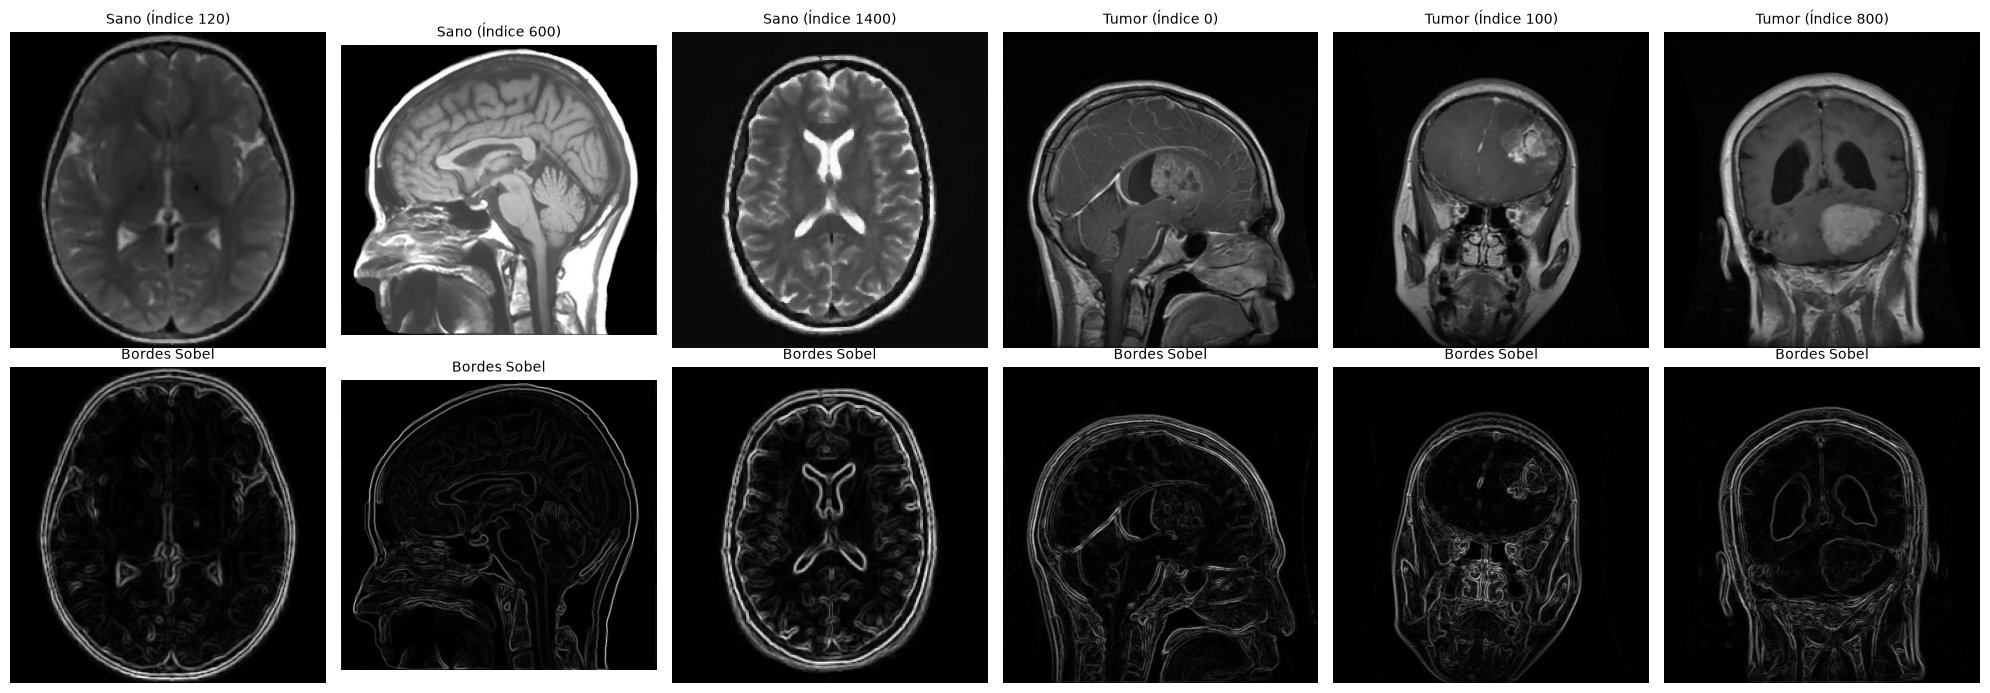

In [31]:
# Sobel aplicado a las 6 imágenes (ya filtradas con mediana)
fig, axes = plt.subplots(2, 6, figsize=(20, 7))
for j in range(6):
    axes[0, j].imshow(imgs_filtradas[j], cmap='gray', vmin=0, vmax=255)
    axes[0, j].set_title(etiquetas[j], fontsize=10)
    axes[1, j].imshow(sobel_mag(imgs_filtradas[j]), cmap='gray')
    axes[1, j].set_title("Bordes Sobel", fontsize=10)
    axes[0, j].axis('off'); axes[1, j].axis('off')
plt.tight_layout()
plt.show()

**Justificación de la decisión:** se elige **Sobel** porque (i) al ser un operador de primera derivada con suavizado incorporado (pesos $1,2,1$) es menos sensible al ruido residual que el Laplaciano, cuya segunda derivada amplifica el ruido; (ii) entrega la magnitud del gradiente, que se puede interpretar directamente como "intensidad del borde"; y (iii) respecto a Prewitt, da más peso a los píxeles vecinos más cercanos al centro, lo que produce bordes algo más limpios. Para esto se aplica sobre la imagen ya filtrada con mediana (Actividad 2). Verifica visualmente la comparación de la figura anterior para confirmar esta elección.